# 03 · Fine-Tune the System & Evaluate on the Test Set
Checklist sections covered:
* **Fine-tune** the shortlisted models (randomised search), treating data-preparation choices as hyper-parameters
* **Try ensembles** (soft voting, stacking)
* Pick the final model and its decision threshold **using validation data only**, then measure it **once** on the
  held-out, out-of-time test set (with confidence intervals and a de-duplicated control)
* Interpret the final model, compare it with the baseline, and translate results into business terms

**Validation scheme for everything in this notebook: forward-in-time (expanding window).** Notebook 02 showed that
random CV — even grouped — is optimistic for a forecasting use case. Here every model is trained on the past and
scored on the next four months: validation periods **May–Aug 2016, Sep–Dec 2016 and Jan–Apr 2017**.

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.evaluation import (best_cost_threshold, best_f1_threshold, evaluate_cv, expected_cost,
                            group_bootstrap, make_cv, time_cv)
from src.features import (FIG_DIR, MODEL_DIR, RANDOM_STATE, TARGET, FeatureEngineer,
                          SegmentRateBaseline, basic_clean, duplicate_groups, load_raw,
                          make_pipeline, make_preprocessor, temporal_split)

sns.set_theme(style="whitegrid")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
data = basic_clean(load_raw())
train, test = temporal_split(data)
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]
groups = duplicate_groups(X_train)
tcv = time_cv(train.arrival_date)
for k, (tr, va) in enumerate(tcv, 1):
    print(f"fold {k}: train {train.arrival_date.iloc[tr].min():%Y-%m} → {train.arrival_date.iloc[tr].max():%Y-%m} "
          f"({len(tr):,} rows) | validate {train.arrival_date.iloc[va].min():%Y-%m} → "
          f"{train.arrival_date.iloc[va].max():%Y-%m} ({len(va):,} rows)")
print(f"test: {len(test):,} rows, {test.arrival_date.min():%Y-%m} → {test.arrival_date.max():%Y-%m}")

fold 1: train 2015-07 → 2016-04 (38,342 rows) | validate 2016-05 → 2016-08 (20,380 rows)
fold 2: train 2015-07 → 2016-08 (58,722 rows) | validate 2016-09 → 2016-12 (19,867 rows)
fold 3: train 2015-07 → 2016-12 (78,589 rows) | validate 2017-01 → 2017-04 (18,442 rows)
test: 22,177 rows, 2017-05 → 2017-08


## 1. Hyper-parameter search
**Method — `RandomizedSearchCV`** (as the checklist recommends over grid search when there are more than a few
hyper-parameters): each booster has 7–8 continuous hyper-parameters; random search explores them far more
efficiently than a grid for the same budget (Bergstra & Bengio, 2012).

**Design choices**
* **Forward-in-time folds** (above) — the search rewards settings that generalise to *future* bookings, not to
  neighbours of the training rows.
* **Data-prep choices are hyper-parameters too**: the rare-category threshold (`min_frequency`) is searched
  jointly with the model parameters.
* **Speed-up without leakage**: `FeatureEngineer` is *stateless* (row-wise formulas, nothing learned from data), so
  we apply it once before the search. All *learned* steps (imputation, encoding, scaling) stay inside the
  searched pipeline and are re-fitted on each training window.
* Budget (2 CPU cores): 20 configurations per booster, 8 for Random Forest and MLP. Scoring = ROC-AUC.

In [3]:
Xfe_train = FeatureEngineer().transform(X_train)


def search(name, model, kind, params, n_iter):
    pipe = Pipeline([("prep", make_preprocessor(kind=kind)), ("model", model)])
    enc = "ordinal" if kind == "ordinal" else "onehot"
    params = {**params, f"prep__cat__{enc}__min_frequency": [10, 30, 50, 100, 200]}
    rs = RandomizedSearchCV(pipe, params, n_iter=n_iter, scoring="roc_auc", cv=tcv,
                            random_state=RANDOM_STATE, n_jobs=2, refit=False, verbose=0)
    t0 = time.time()
    rs.fit(Xfe_train, y_train)
    scores = rs.cv_results_["mean_test_score"]
    print(f"{name:14s} best forward-in-time AUC = {rs.best_score_:.4f}  (worst config {scores.min():.4f}; "
          f"{n_iter} configs, {time.time() - t0:.0f}s)")
    return rs


searches = {}
searches["XGBoost"] = search(
    "XGBoost", XGBClassifier(tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, eval_metric="logloss"),
    "ordinal",
    {"model__n_estimators": randint(200, 1000), "model__learning_rate": loguniform(0.02, 0.2),
     "model__max_depth": randint(4, 11), "model__min_child_weight": loguniform(0.5, 20),
     "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.4, 0.6),
     "model__gamma": uniform(0, 1), "model__reg_lambda": loguniform(1e-2, 10)},
    n_iter=20)
searches["LightGBM"] = search(
    "LightGBM", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1, subsample_freq=1),
    "ordinal",
    {"model__n_estimators": randint(200, 1200), "model__learning_rate": loguniform(0.02, 0.2),
     "model__num_leaves": randint(15, 256), "model__min_child_samples": randint(5, 80),
     "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.4, 0.6),
     "model__reg_lambda": loguniform(1e-3, 10)},
    n_iter=20)
searches["Random Forest"] = search(
    "Random Forest", RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE),
    "ordinal",
    {"model__n_estimators": [200, 300], "model__max_depth": [None, 12, 20, 30],
     "model__min_samples_leaf": randint(1, 10), "model__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=8)
searches["MLP"] = search(
    "MLP", MLPClassifier(early_stopping=True, max_iter=200, random_state=RANDOM_STATE),
    "onehot",
    {"model__hidden_layer_sizes": [(64, 32), (128, 64), (256, 128), (128, 64, 32)],
     "model__alpha": loguniform(1e-5, 1e-2), "model__learning_rate_init": loguniform(3e-4, 3e-3),
     "model__batch_size": [256, 512]},
    n_iter=8)

XGBoost        best forward-in-time AUC = 0.8585  (worst config 0.8280; 20 configs, 134s)


LightGBM       best forward-in-time AUC = 0.8481  (worst config 0.8246; 20 configs, 261s)


Random Forest  best forward-in-time AUC = 0.8489  (worst config 0.8249; 8 configs, 185s)


MLP            best forward-in-time AUC = 0.8530  (worst config 0.8392; 8 configs, 234s)


In [4]:
best_params = {n: s.best_params_ for n, s in searches.items()}
pd.DataFrame({n: {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in p.items()}
              for n, p in best_params.items()}).fillna("")

,XGBoost,LightGBM,Random Forest,MLP
colsample_bytree,0.8082,0.5091,,
gamma,0.4505,,,
learning_rate,0.0206,0.0305,,
max_depth,4.0,,12,
min_child_weight,17.6186,,,
n_estimators,441.0,221.0,300,
reg_lambda,0.1433,0.0012,,
subsample,0.6064,0.8099,,
prep__cat__ordinal__min_frequency,30.0,30.0,100,
min_child_samples,,62.0,,


**Takeaways:** validated forward in time, the search prefers **more conservative models** than a random split
would: XGBoost won with **shallow trees (depth 4)**, a large `min_child_weight` (17.6) and a small learning rate
(0.02, 441 trees); Random Forest with depth 12. Simpler trees generalise better to a future whose booking mix has
shifted. A rare-level threshold of **30** was best for both boosters (100 for RF, 50 for the MLP). The spread between
the best and worst configuration (≈ 0.02–0.03 AUC for the trees) shows that tuning matters here.

## 2. Tuned vs default models (same forward-in-time folds)

In [5]:
kinds = {"XGBoost": "ordinal", "LightGBM": "ordinal", "Random Forest": "ordinal", "MLP": "onehot"}
base_models = {
    "XGBoost": XGBClassifier(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss"),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, subsample_freq=1),
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    "MLP": MLPClassifier(early_stopping=True, max_iter=200, random_state=RANDOM_STATE),
}
default_settings = {"XGBoost": {}, "LightGBM": {},
                    "Random Forest": {"model__n_estimators": 200},
                    "MLP": {"model__hidden_layer_sizes": (64, 32)}}


def tuned_pipeline(name, use_country=True, booking_time=True):
    pipe = make_pipeline(clone(base_models[name]), kind=kinds[name], use_country=use_country,
                         booking_time=booking_time)
    return pipe.set_params(**best_params[name])


rows, oof, fold_scores = [], {}, {}
for name in base_models:
    d_pipe = make_pipeline(clone(base_models[name]), kind=kinds[name]).set_params(**default_settings[name])
    f_def, _ = evaluate_cv(d_pipe, X_train, y_train, groups, cv=tcv, name=name)
    f_tun, p = evaluate_cv(tuned_pipeline(name), X_train, y_train, groups, cv=tcv, name=name)
    oof[name] = p
    fold_scores[name] = f_tun.roc_auc.values
    rows.append({"model": name, "default ROC-AUC": f_def.roc_auc.mean(),
                 "tuned ROC-AUC": f_tun.roc_auc.mean(), "tuned std": f_tun.roc_auc.std(),
                 "gain": f_tun.roc_auc.mean() - f_def.roc_auc.mean(), "tuned PR-AUC": f_tun.pr_auc.mean(),
                 "AUC per fold (May–Aug 16 / Sep–Dec 16 / Jan–Apr 17)": " / ".join(f"{v:.3f}" for v in f_tun.roc_auc)})
tuned = pd.DataFrame(rows).set_index("model").sort_values("tuned ROC-AUC", ascending=False)
tuned.round(4)

,default ROC-AUC,tuned ROC-AUC,tuned std,gain,tuned PR-AUC,AUC per fold (May–Aug 16 / Sep–Dec 16 / Jan–Apr 17)
model,,,,,,
XGBoost,0.8408,0.8585,0.0255,0.0177,0.8068,0.830 / 0.865 / 0.880
MLP,0.8472,0.8530,0.0079,0.0058,0.8045,0.844 / 0.858 / 0.858
Random Forest,0.8317,0.8489,0.0208,0.0172,0.7990,0.828 / 0.850 / 0.869
LightGBM,0.8275,0.8481,0.0286,0.0206,0.7989,0.819 / 0.850 / 0.876


**Takeaways:**
* Tuning improved every tree model by **+0.017 to +0.021 ROC-AUC** on future windows (LightGBM 0.828 → 0.848,
  XGBoost 0.841 → 0.859, RF 0.832 → 0.849) — far more than under random CV, because the defaults overfit the
  past. The MLP gained +0.006.
* **Tuned XGBoost is best** (0.859), the MLP second (0.853): the shallow, regularised models transfer best.
* Every model improves from window 1 to window 3 (≈ 0.82 → 0.88) simply because it has more training history.

## 3. Ensembles
* **Soft voting** — average the predicted probabilities of the tuned models (no extra fitting).
* **Stacking** — a logistic-regression meta-model learns how to weight the four models' out-of-fold
  probabilities; to score it honestly it is itself fitted *forward in time*: for each validation window it is
  trained on the earlier windows' predictions (so it can only be scored on the 2nd and 3rd windows).

All candidates are compared with the mean ROC-AUC over the validation windows they can be scored on.

In [6]:
covered = ~np.isnan(oof["LightGBM"])
fold_of = np.full(len(y_train), -1)
for k, (_, va) in enumerate(tcv):
    fold_of[va] = k
oof_df = pd.DataFrame(oof)
cands = {n: oof_df[n].values for n in oof}
cands["Voting (XGB+LGBM+RF+MLP)"] = oof_df.mean(axis=1).values
cands["Voting (XGB+LGBM)"] = oof_df[["XGBoost", "LightGBM"]].mean(axis=1).values
cands["Voting (XGB+RF+MLP)"] = oof_df[["XGBoost", "Random Forest", "MLP"]].mean(axis=1).values
logit = np.log(oof_df.clip(1e-4, 1 - 1e-4) / (1 - oof_df.clip(1e-4, 1 - 1e-4)))
stack = np.full(len(y_train), np.nan)
for k in [1, 2]:
    fit_rows, pred_rows = (fold_of >= 0) & (fold_of < k), fold_of == k
    meta = LogisticRegression(max_iter=1000).fit(logit[fit_rows], y_train[fit_rows])
    stack[pred_rows] = meta.predict_proba(logit[pred_rows])[:, 1]
cands["Stacking (LogReg meta)"] = stack
print("stacking weights (last window):", dict(zip(oof_df.columns, meta.coef_[0].round(2))))


def window_auc(p, ks):
    return np.mean([roc_auc_score(y_train[fold_of == k], p[fold_of == k]) for k in ks])


cv_table = pd.DataFrame({n: {"ROC-AUC, windows 2+3": window_auc(p, [1, 2]),
                             "ROC-AUC, all 3 windows": (window_auc(p, [0, 1, 2]) if not n.startswith("Stacking")
                                                        else np.nan)}
                         for n, p in cands.items()}).T.sort_values("ROC-AUC, windows 2+3", ascending=False)
cv_table.round(4)

stacking weights (last window): {'XGBoost': np.float64(0.25), 'LightGBM': np.float64(-0.06), 'Random Forest': np.float64(0.31), 'MLP': np.float64(0.29)}


,"ROC-AUC, windows 2+3","ROC-AUC, all 3 windows"
XGBoost,0.8725,0.8585
Voting (XGB+LGBM),0.8724,0.8580
Voting (XGB+LGBM+RF+MLP),0.8722,0.8619
Voting (XGB+RF+MLP),0.8715,0.8623
Stacking (LogReg meta),0.8696,NaN
LightGBM,0.8627,0.8481
Random Forest,0.8595,0.8489
MLP,0.8575,0.8530


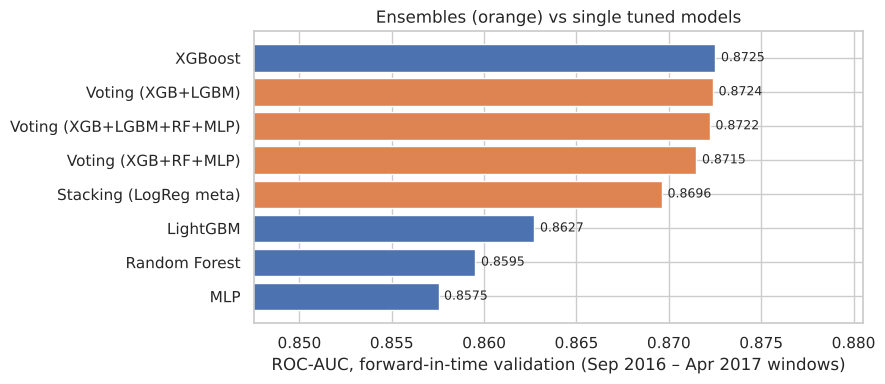

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
c = cv_table["ROC-AUC, windows 2+3"][::-1]
ax.barh(c.index, c.values, color=["#DD8452" if ("Voting" in n or "Stacking" in n) else "#4C72B0" for n in c.index])
for i, v in enumerate(c.values):
    ax.text(v + 0.0003, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(c.min() - 0.01, c.max() + 0.008)
ax.set_xlabel("ROC-AUC, forward-in-time validation (Sep 2016 – Apr 2017 windows)")
ax.set_title("Ensembles (orange) vs single tuned models")
fig.tight_layout(); save(fig, "ensemble_comparison"); plt.show()

**Takeaways:** no ensemble beats tuned XGBoost on the windows every candidate can be scored on (best: voting
XGB+LGBM 0.8724 vs XGBoost 0.8725). Stacking is lower (0.870) and its meta-model even gives LightGBM a negative
weight — the models are too correlated for combining to help. Ensembling *worked* technically but adds no value.

### Choosing the final model (on validation evidence only)
Rule fixed *before* looking at the test set: **highest ROC-AUC on windows 2+3 (the windows every candidate can be
scored on); if several options are within 0.002, prefer the simplest** (fewer models → cheaper to run, retrain
and explain).

In [8]:
ranking = cv_table["ROC-AUC, windows 2+3"]
best = ranking.idxmax()
close = [n for n in ranking.index if ranking[n] >= ranking[best] - 0.002]
complexity = {n: (1 if n in oof else 2 if "XGB+LGBM)" in n else 3 if "XGB+RF+MLP" in n else 4) for n in ranking.index}
FINAL = min(close, key=lambda n: (complexity[n], -ranking[n]))
CV_AUC = cv_table.loc[FINAL, "ROC-AUC, all 3 windows"]
print(f"best: {best} ({ranking[best]:.4f}); within 0.002: {close}")
print(f"chosen: {FINAL}  — forward-in-time ROC-AUC {ranking[FINAL]:.4f} (windows 2+3), {CV_AUC:.4f} (all 3 windows)")

best: XGBoost (0.8725); within 0.002: ['XGBoost', 'Voting (XGB+LGBM)', 'Voting (XGB+LGBM+RF+MLP)', 'Voting (XGB+RF+MLP)']
chosen: XGBoost  — forward-in-time ROC-AUC 0.8725 (windows 2+3), 0.8585 (all 3 windows)


→ **Final model: tuned XGBoost** — the best single model, and the simplest option within 0.002 of the best.
One model means faster scoring and retraining and a simpler explanation for the revenue team. Its forward-in-time
validation ROC-AUC is **0.859** (all three windows).

### Decision threshold from a business cost (chosen on validation data, not on test)
A probability is not a decision. Flagging a booking triggers an action (reminder, "confirm your stay" offer,
deposit request); not flagging a cancellation leaves a room empty. We choose the threshold that minimises

`cost = missed cancellations × 1 + false alarms × c`, where **c = cost of a false alarm ÷ cost of an empty room**.

* **Base case c = 0.5** — for the *targeted-action* use, a false alarm costs a contact, possibly a discount and some
  guest goodwill: assumed to be half the value of an empty room. *This is an assumption, not data.*
* **c = 2–4** describes an *aggressive overbooking* use, where a false alarm can mean walking a guest to another
  hotel. We report the whole range so the revenue team can pick their own c.

The threshold is chosen on the out-of-fold predictions of the forward-in-time windows.

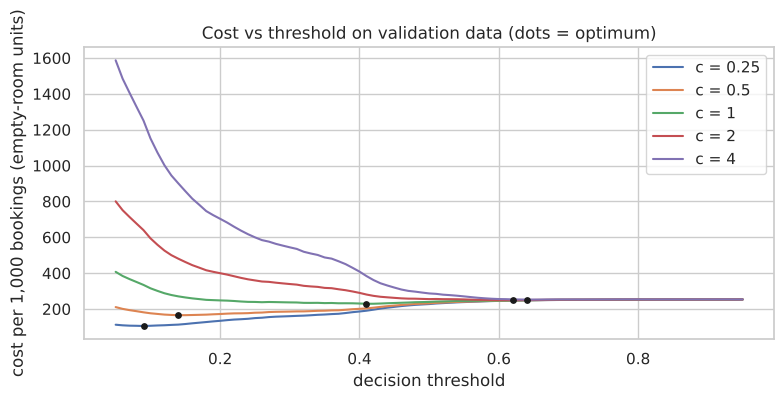

,threshold,precision,recall,share of bookings flagged
c,,,,
0.25,0.09,0.527,0.922,0.645
0.50,0.14,0.595,0.836,0.518
1.00,0.41,0.787,0.518,0.243
2.00,0.62,0.985,0.332,0.124
4.00,0.64,0.991,0.327,0.122


In [9]:
p_final_oof = cands[FINAL] if FINAL in oof else None
mask = covered if FINAL in oof else (fold_of >= 1)
y_cov, p_cov = y_train[mask].values, np.asarray(cands[FINAL])[mask]
C_GRID = [0.25, 0.5, 1, 2, 4]
thr_by_c = {}
fig, ax = plt.subplots(figsize=(8, 4))
grid = np.linspace(0.05, 0.95, 91)
for c in C_GRID:
    t, costs = best_cost_threshold(y_cov, p_cov, c, grid)
    thr_by_c[c] = t
    ax.plot(grid, costs / len(y_cov) * 1000, label=f"c = {c}")
    ax.scatter([t], [costs.min() / len(y_cov) * 1000], color="k", zorder=3, s=15)
ax.set_xlabel("decision threshold"); ax.set_ylabel("cost per 1,000 bookings (empty-room units)")
ax.set_title("Cost vs threshold on validation data (dots = optimum)"); ax.legend()
fig.tight_layout(); save(fig, "cost_threshold"); plt.show()

BASE_C = 0.5
THRESHOLD = thr_by_c[BASE_C]
f1_thr, _ = best_f1_threshold(y_cov, p_cov)
pd.DataFrame({"threshold": thr_by_c,
              "precision": {c: precision_score(y_cov, p_cov >= t) for c, t in thr_by_c.items()},
              "recall": {c: recall_score(y_cov, p_cov >= t) for c, t in thr_by_c.items()},
              "share of bookings flagged": {c: (p_cov >= t).mean() for c, t in thr_by_c.items()}}
             ).rename_axis("c").round(3)

In [10]:
print(f"base case c = {BASE_C}: threshold = {THRESHOLD:.2f}   (for reference, the F1-optimal threshold is {f1_thr:.2f})")

base case c = 0.5: threshold = 0.14   (for reference, the F1-optimal threshold is 0.15)


**Takeaways:**
* With **c = 0.5** (a false alarm costs half an empty room) the cost-optimal threshold is **0.14**: flag about half of
  all bookings, catching 84% of cancellations at 60% precision. When contacting a guest is cheap, it pays to contact
  many. (The F1-optimal threshold, 0.15, happens to be almost the same.)
* As false alarms get more expensive the threshold rises: 0.41 at c = 1, 0.62–0.64 at c = 2–4, where only the
  near-certain cancellations (mostly non-refundable group blocks) are flagged.
* The threshold for c = 0.5 is far below the textbook value for calibrated probabilities (c / (1 + c) = 0.33):
  a sign the model **under-predicts** risk on later periods (see calibration, §6c).
* The cost curves are flat around their minimum, so the exact threshold matters less than the choice of c —
  **which the revenue team must set**. We fixed c = 0.5 before looking at the test set.

## 4. Train the final system on the full training set

In [11]:
def build_final(use_country=True, booking_time=True):
    if FINAL in oof:
        return tuned_pipeline(FINAL, use_country, booking_time)
    if FINAL.startswith("Voting"):
        names = {"Voting (XGB+LGBM+RF+MLP)": list(oof), "Voting (XGB+LGBM)": ["XGBoost", "LightGBM"],
                 "Voting (XGB+RF+MLP)": ["XGBoost", "Random Forest", "MLP"]}[FINAL]
        return VotingClassifier([(n, tuned_pipeline(n, use_country, booking_time)) for n in names], voting="soft")
    raise ValueError("stacking chosen: build with sklearn StackingClassifier")


t0 = time.time()
final_model = build_final().fit(X_train, y_train)
print(f"final model '{FINAL}' trained in {time.time() - t0:.0f}s")

final model 'XGBoost' trained in 3s


## 5. 🔒 One-time evaluation on the out-of-time test set (May – Aug 2017)
From here on nothing is tuned. Baselines are fitted on the same training data; the business rule's threshold is
chosen with the same cost function (c = 0.5) on the training data.

In [12]:
baseline = SegmentRateBaseline().fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
p_base = baseline.predict_proba(X_test)[:, 1]
base_thr, _ = best_cost_threshold(y_train.values, baseline.predict_proba(X_train)[:, 1], BASE_C)


def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "Accuracy": (pred == y).mean(), "threshold": thr}


test_results = pd.DataFrame({
    "Dummy (always 'shows up')": {"ROC-AUC": 0.5, "PR-AUC": y_test.mean(), "F1": 0.0, "Precision": 0.0,
                                  "Recall": 0.0, "Accuracy": 1 - y_test.mean(), "threshold": np.nan},
    "Business rule (segment rate)": report(y_test, p_base, base_thr),
    f"Final model: {FINAL}": report(y_test, p_test, THRESHOLD),
}).T
test_results["validation ROC-AUC (forward-in-time)"] = [np.nan, np.nan, CV_AUC]
test_results.round(4)

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,threshold,validation ROC-AUC (forward-in-time)
Dummy (always 'shows up'),0.5000,0.4057,0.0000,0.0000,0.0000,0.5943,NaN,NaN
Business rule (segment rate),0.6911,0.6112,0.5748,0.5203,0.6420,0.6146,0.33,NaN
Final model: XGBoost,0.8399,0.7912,0.7015,0.5518,0.9625,0.6676,0.14,0.8585


### How certain are these numbers? Bootstrap 95% intervals
Resampling the test bookings 300 times — whole duplicate groups at a time, so identical rows move together.

In [13]:
test_groups = duplicate_groups(X_test)
ci_auc = group_bootstrap(y_test, {"model": p_test, "rule": p_base}, test_groups, roc_auc_score)
ci_ap = group_bootstrap(y_test, {"model": p_test, "rule": p_base}, test_groups, average_precision_score)
pd.DataFrame({"ROC-AUC 95% CI": {k: f"{v[0]:.3f} – {v[1]:.3f}" for k, v in ci_auc.items()},
              "PR-AUC 95% CI": {k: f"{v[0]:.3f} – {v[1]:.3f}" for k, v in ci_ap.items()}})

,ROC-AUC 95% CI,PR-AUC 95% CI
model,0.829 – 0.852,0.767 – 0.814
rule,0.674 – 0.711,0.577 – 0.644
model − rule,0.138 – 0.159,0.167 – 0.193


**Takeaways:** the test ROC-AUC is **0.840 (95% CI 0.829–0.852)** vs **0.691 (0.674–0.711)** for the rule, and the
paired difference is **+0.138 to +0.159** — the model is better than today's rule with high confidence.

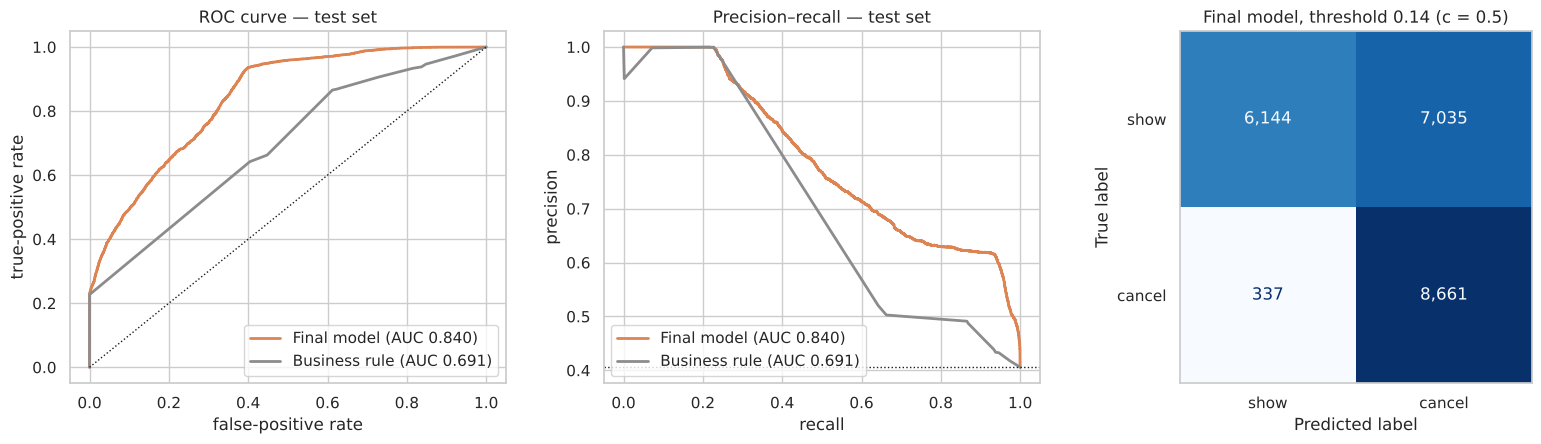

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for p, lab, col in [(p_test, f"Final model (AUC {roc_auc_score(y_test, p_test):.3f})", "#DD8452"),
                    (p_base, f"Business rule (AUC {roc_auc_score(y_test, p_base):.3f})", "#8C8C8C")]:
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=lab, color=col, lw=2)
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=lab, color=col, lw=2)
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("false-positive rate"); axes[0].set_ylabel("true-positive rate")
axes[0].set_title("ROC curve — test set"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision–recall — test set"); axes[1].legend(loc="lower left")
ConfusionMatrixDisplay(confusion_matrix(y_test, p_test >= THRESHOLD), display_labels=["show", "cancel"]).plot(
    ax=axes[2], colorbar=False, values_format=",", cmap="Blues"); axes[2].grid(False)
axes[2].set_title(f"Final model, threshold {THRESHOLD:.2f} (c = {BASE_C})")
fig.tight_layout(); save(fig, "test_performance"); plt.show()

### De-duplicated control
28% of rows are repeated group bookings, which are easy to predict. How good is the model on **single bookings**
only (test rows that have no model-identical twin in the test set)?

In [15]:
dup_size = pd.Series(test_groups).map(pd.Series(test_groups).value_counts()).values
single = dup_size == 1
dedup = pd.DataFrame({
    "all test bookings": {"n": len(y_test), "cancel rate": y_test.mean(),
                          "model ROC-AUC": roc_auc_score(y_test, p_test), "rule ROC-AUC": roc_auc_score(y_test, p_base),
                          "model PR-AUC": average_precision_score(y_test, p_test),
                          "rule PR-AUC": average_precision_score(y_test, p_base)},
    "single bookings only": {"n": int(single.sum()), "cancel rate": y_test[single].mean(),
                             "model ROC-AUC": roc_auc_score(y_test[single], p_test[single]),
                             "rule ROC-AUC": roc_auc_score(y_test[single], p_base[single]),
                             "model PR-AUC": average_precision_score(y_test[single], p_test[single]),
                             "rule PR-AUC": average_precision_score(y_test[single], p_base[single])}}).T
dedup.round(3)

,n,cancel rate,model ROC-AUC,rule ROC-AUC,model PR-AUC,rule PR-AUC
all test bookings,22177.0,0.406,0.840,0.691,0.791,0.611
single bookings only,15632.0,0.338,0.782,0.609,0.607,0.408


**Takeaways:** on **single bookings** (70% of the test set; base rate 34%) the model drops to **ROC-AUC 0.78 /
PR-AUC 0.61** — repeated group blocks are easy and lift the headline score. But the rule drops even more (0.61 /
0.41), so the model's advantage holds on the hard, individual bookings too (+0.17 AUC).

### Sensitivity checks (reported for information — not used for model selection)
Same pipeline and hyper-parameters, one assumption changed at a time:
* **without `country`** — `country` may be partially leaky (see notebook 01 §5, §7). Conservative lower bound.
* **with the post-booking columns** (parking, special requests, booking changes) — what the model could reach
  if this information were available at booking time. Upper bound; *not* deployable as such, because most
  cancellations happen weeks before arrival (notebook 01 §6).

In [16]:
final_nc = build_final(use_country=False).fit(X_train, y_train)
p_test_nc = final_nc.predict_proba(X_test)[:, 1]
final_ub = build_final(booking_time=False).fit(X_train, y_train)
p_test_ub = final_ub.predict_proba(X_test)[:, 1]
sens = pd.DataFrame({"main model (booking-time features)": report(y_test, p_test, THRESHOLD),
                     "without country (lower bound)": report(y_test, p_test_nc, THRESHOLD),
                     "+ post-booking columns (upper bound)": report(y_test, p_test_ub, THRESHOLD),
                     "business rule": report(y_test, p_base, base_thr)}).T
sens.round(4)

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,threshold
main model (booking-time features),0.8399,0.7912,0.7015,0.5518,0.9625,0.6676,0.14
without country (lower bound),0.7950,0.7614,0.6207,0.4577,0.9639,0.5219,0.14
+ post-booking columns (upper bound),0.8778,0.8340,0.7266,0.5820,0.9667,0.7048,0.14
business rule,0.6911,0.6112,0.5748,0.5203,0.6420,0.6146,0.33


**Takeaways:**
* **Upper bound:** if parking, special requests and booking changes were known at booking time, the same model
  would reach **0.878** ROC-AUC (+0.04) — the cost of predicting early, and the value of capturing these signals
  earlier (e.g. asking for parking / requests in the booking form).
* **Lower bound:** without `country` the test ROC-AUC drops from 0.840 to **0.795** — still far above the rule (0.691).
* Realistic range for a booking-time model on future bookings: **≈ 0.80–0.84 ROC-AUC**, vs 0.69 today.

## 6. What does this mean for the hotels?
### 6a. Cost, rooms and euros at the chosen threshold
Cost per 1,000 bookings (empty-room units) for each policy, with thresholds chosen on training data for each c;
and the **room revenue of the cancelled bookings that are flagged in advance** (ADR × nights).

In [17]:
rule_thr_by_c = {c: best_cost_threshold(y_train.values, baseline.predict_proba(X_train)[:, 1], c)[0] for c in C_GRID}
cost_rows = []
for c in C_GRID:
    n = len(y_test) / 1000
    cost_rows.append({"c": c,
                      "flag nobody": expected_cost(y_test, np.zeros(len(y_test)), c) / n,
                      "flag everybody": expected_cost(y_test, np.ones(len(y_test)), c) / n,
                      "business rule": expected_cost(y_test, p_base >= rule_thr_by_c[c], c) / n,
                      "model": expected_cost(y_test, p_test >= thr_by_c[c], c) / n})
cost_table = pd.DataFrame(cost_rows).set_index("c")
cost_table["model saving vs best simple policy"] = 1 - cost_table["model"] / cost_table[
    ["flag nobody", "flag everybody", "business rule"]].min(axis=1)
display(cost_table.round(1).assign(**{"model saving vs best simple policy":
                                      cost_table["model saving vs best simple policy"].map("{:.0%}".format)}))

value = test.adr * (test.stays_in_weekend_nights + test.stays_in_week_nights)
canc = y_test.values == 1
flag_m, flag_b = p_test >= THRESHOLD, p_base >= base_thr
eur = pd.DataFrame({
    "model": {"bookings flagged": flag_m.sum(), "cancellations caught": (flag_m & canc).sum(),
              "€ of cancelled revenue flagged in advance": value[flag_m & canc].sum(),
              "share of cancelled revenue flagged": value[flag_m & canc].sum() / value[canc].sum()},
    "business rule": {"bookings flagged": flag_b.sum(), "cancellations caught": (flag_b & canc).sum(),
                      "€ of cancelled revenue flagged in advance": value[flag_b & canc].sum(),
                      "share of cancelled revenue flagged": value[flag_b & canc].sum() / value[canc].sum()}}).T
print(f"total room revenue of cancelled test bookings: €{value[canc].sum():,.0f}")
eur_fmt = eur.copy().astype(object)
eur_fmt["bookings flagged"] = eur["bookings flagged"].map("{:,.0f}".format)
eur_fmt["cancellations caught"] = eur["cancellations caught"].map("{:,.0f}".format)
eur_fmt["€ of cancelled revenue flagged in advance"] = eur["€ of cancelled revenue flagged in advance"].map("€{:,.0f}".format)
eur_fmt["share of cancelled revenue flagged"] = eur["share of cancelled revenue flagged"].map("{:.0%}".format)
eur_fmt

,flag nobody,flag everybody,business rule,model,model saving vs best simple policy
c,,,,,
0.25,405.7,148.6,145.9,106.7,27%
0.50,405.7,297.1,265.3,173.8,34%
1.00,405.7,594.3,313.8,273.5,13%
2.00,405.7,1188.5,313.8,310.5,1%
4.00,405.7,2377.1,313.9,318.5,-1%


total room revenue of cancelled test bookings: €4,987,228


,bookings flagged,cancellations caught,€ of cancelled revenue flagged in advance,share of cancelled revenue flagged
model,"15,696","8,661","€4,823,719",97%
business rule,"11,104","5,777","€2,597,999",52%


**Takeaways:**
* When false alarms are cheap (**c ≤ 1**) the model **cuts the cost by 13–34%** vs the best simple policy (flag
  nobody, flag everybody, or the rule). For c = 0.5 that is 174 vs 265 empty-room units per 1,000 bookings.
* When false alarms are expensive (**c ≥ 2**, e.g. walking an overbooked guest) the model and the rule are about
  equal: both only act on the obvious non-refundable group blocks. **The model's value is in low-cost actions**
  (reminders, confirmation offers, soft overbooking), not in aggressive overbooking.
* At c = 0.5 the model flags 71% of test bookings and those include 97% of the cancelled room revenue
  (€4.8M of €5.0M), vs 52% for the rule — but that is a consequence of contacting many guests; the
  fixed-effort view below is the fairer comparison.

### 6b. Targeted actions: how many cancellations for a fixed effort?
If the team can only contact a fixed share of bookings, which share of all cancellations does each approach reach?

In [18]:
def capture_at(p, k_share):
    k = int(len(p) * k_share)
    top = np.argsort(-p)[:k]
    return y_test.values[top].sum() / y_test.sum(), y_test.values[top].mean()


rows = []
for share in [0.10, 0.20, 0.30, 0.40]:
    r_m, p_m = capture_at(p_test, share)
    r_b, p_b = capture_at(p_base + np.random.default_rng(0).uniform(0, 1e-6, len(p_base)), share)  # tie-break
    rows.append({"flag top % of bookings": f"{share:.0%}", "model: % of cancellations caught": r_m,
                 "model: precision": p_m, "rule: % of cancellations caught": r_b, "rule: precision": p_b})
capture = pd.DataFrame(rows).set_index("flag top % of bookings")
(capture * 100).round(1)

,model: % of cancellations caught,model: precision,rule: % of cancellations caught,rule: precision
flag top % of bookings,,,,
10%,24.2,98.2,23.6,95.8
20%,41.2,83.6,33.9,68.7
30%,54.7,73.9,43.8,59.3
40%,66.8,67.8,53.8,54.6


**Takeaway:** with the same effort, the model finds far more cancellations. If the team contacts the **30%
riskiest bookings**, the model catches **55% of all cancellations (74% of the contacted bookings really
cancel)**, against 44% (59% precision) for the segment rule. At 10% the two are similar — both find the obvious
Non-Refund blocks — the model's value is in the *next* tiers of risk.

### 6c. Overbooking: can we forecast how many rooms will be freed per night?
Summing the predicted probabilities of all bookings arriving on a given date gives the **expected number of
cancellations** for that date. This only works if the probabilities are **calibrated**, so we check that first.

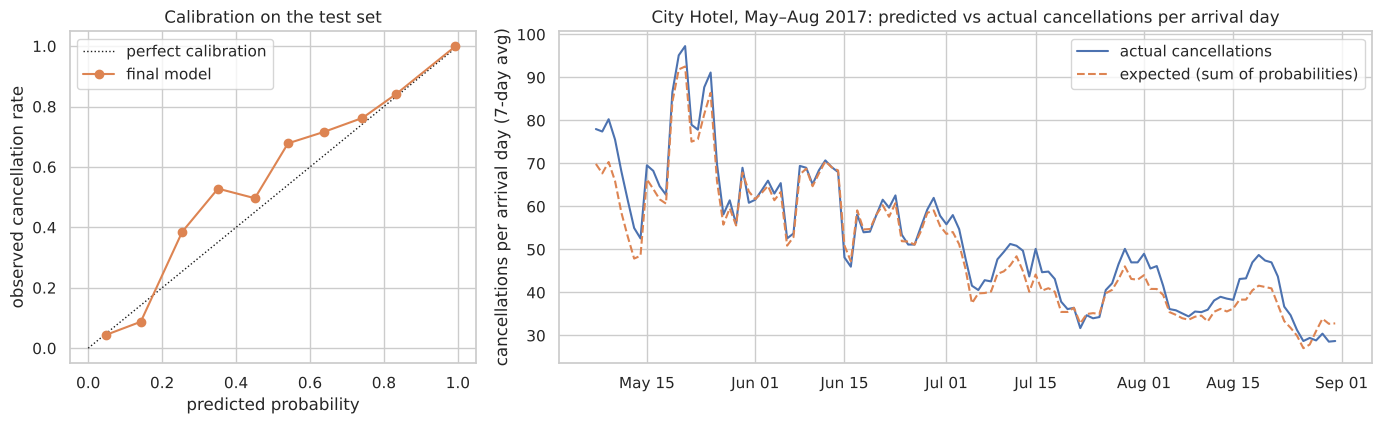

mean predicted probability 0.361 vs actual cancellation rate 0.406
Weighted absolute error of daily expected cancellations (both hotels): 15.5%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 2]})
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10)
axes[0].plot([0, 1], [0, 1], "k:", lw=1, label="perfect calibration")
axes[0].plot(mean_pred, frac_pos, "o-", color="#DD8452", label="final model")
axes[0].set_xlabel("predicted probability"); axes[0].set_ylabel("observed cancellation rate")
axes[0].set_title("Calibration on the test set"); axes[0].legend()
daily = test.assign(p=p_test).groupby(["arrival_date", "hotel"]).agg(actual=(TARGET, "sum"), expected=("p", "sum"))
city = daily.xs("City Hotel", level="hotel").rolling(7).mean()
axes[1].plot(city.index, city["actual"], label="actual cancellations", color="#4C72B0")
axes[1].plot(city.index, city["expected"], label="expected (sum of probabilities)", color="#DD8452", ls="--")
axes[1].set_ylabel("cancellations per arrival day (7-day avg)")
axes[1].set_title("City Hotel, May–Aug 2017: predicted vs actual cancellations per arrival day")
axes[1].legend(); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout(); save(fig, "overbooking_forecast"); plt.show()
mape = (daily["expected"] - daily["actual"]).abs().sum() / daily["actual"].sum()
print(f"mean predicted probability {p_test.mean():.3f} vs actual cancellation rate {y_test.mean():.3f}")
print(f"Weighted absolute error of daily expected cancellations (both hotels): {mape:.1%}")

**Takeaways:**
* The daily forecast **tracks the shape** of actual cancellations closely (peaks and troughs line up; daily error
  ≈ 16%), which is what an overbooking decision needs, but it is **slightly but consistently too low**: on average
  it predicts 36.1% while 40.6% of test bookings cancelled.
* Cause: the cancellation rate rose in 2017 (§7). **Before using the probabilities for overbooking, they must be
  re-calibrated on recent data** (e.g. isotonic calibration on the last 2–3 months), and the model retrained monthly.

## 7. How far can we trust validation scores? (diagnosis only — the model is not changed)
Three estimates of the same tuned model, plus the test: (a) random grouped 5-fold CV (as in notebook 02),
(b) our forward-in-time validation, (c) the test month by month; and (d) how the booking mix changed.

In [20]:
f_rand, _ = evaluate_cv(build_final(), X_train, y_train, groups, name="random grouped CV")
auc_rand = f_rand.roc_auc.mean()
print(f"(a) random grouped 5-fold CV: {auc_rand:.3f}   (b) forward-in-time validation: {CV_AUC:.3f}   "
      f"test: {roc_auc_score(y_test, p_test):.3f}")

monthly = test.assign(p=p_test).groupby(test.arrival_date.dt.strftime("%Y-%m")).apply(
    lambda g: pd.Series({"ROC-AUC": roc_auc_score(g[TARGET], g.p), "actual rate": g[TARGET].mean(),
                         "mean predicted": g.p.mean()}))
print("\n(c) test performance by arrival month"); display(monthly.round(3))

mix = pd.DataFrame({
    "share train": train.market_segment.value_counts(normalize=True),
    "share test": test.market_segment.value_counts(normalize=True),
    "cancel rate train": train.groupby("market_segment")[TARGET].mean(),
    "cancel rate test": test.groupby("market_segment")[TARGET].mean()}).loc[
    ["Online TA", "Offline TA/TO", "Groups", "Direct", "Corporate"]]
extra = pd.DataFrame({
    "share train": [(train.deposit_type == "Non Refund").mean(), (train.country == "PRT").mean()],
    "share test": [(test.deposit_type == "Non Refund").mean(), (test.country == "PRT").mean()],
    "cancel rate train": [train.loc[train.deposit_type == "No Deposit", TARGET].mean(), np.nan],
    "cancel rate test": [test.loc[test.deposit_type == "No Deposit", TARGET].mean(), np.nan]},
    index=["Non-Refund deposits (rate = No-Deposit rate)", "Country = PRT"])
print("\n(d) booking mix"); display((pd.concat([mix, extra]) * 100).round(1))

(a) random grouped 5-fold CV: 0.904   (b) forward-in-time validation: 0.858   test: 0.840

(c) test performance by arrival month


,ROC-AUC,actual rate,mean predicted
arrival_date,,,
2017-05,0.883,0.438,0.390
2017-06,0.860,0.432,0.393
2017-07,0.805,0.374,0.325
2017-08,0.783,0.368,0.325



(d) booking mix


,share train,share test,cancel rate train,cancel rate test
Online TA,44.7,59.0,35.0,42.7
Offline TA/TO,21.3,16.0,34.4,34.0
Groups,18.0,10.4,60.2,67.7
Direct,10.4,11.1,14.6,18.7
Corporate,4.8,2.7,17.9,25.8
Non-Refund deposits (rate = No-Deposit rate),12.9,9.1,26.9,34.5
Country = PRT,43.2,29.5,NaN,NaN


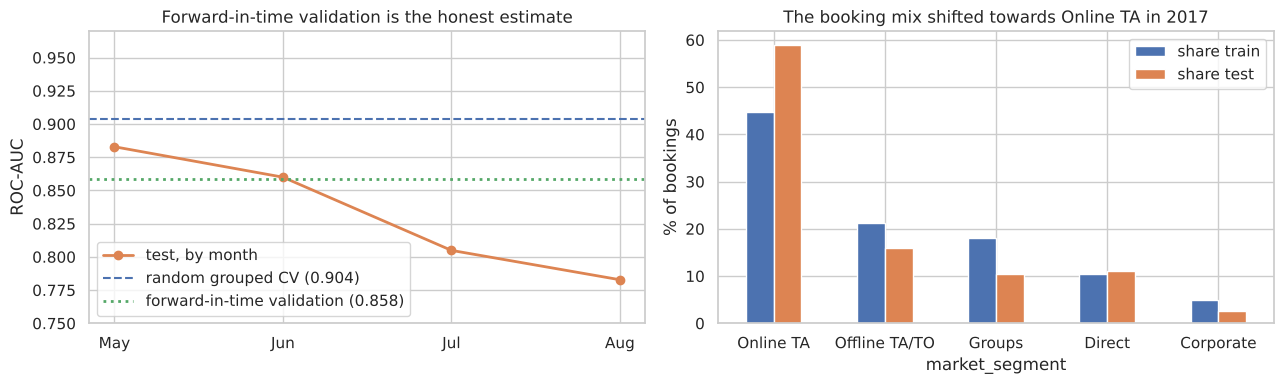

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mm = monthly.copy(); mm.index = pd.to_datetime(mm.index)
axes[0].plot(mm.index.strftime("%b"), mm["ROC-AUC"], "o-", color="#DD8452", lw=2, label="test, by month")
axes[0].axhline(auc_rand, color="#4C72B0", ls="--", label=f"random grouped CV ({auc_rand:.3f})")
axes[0].axhline(CV_AUC, color="#55A868", ls=":", lw=2, label=f"forward-in-time validation ({CV_AUC:.3f})")
axes[0].set_ylim(0.75, 0.97); axes[0].set_ylabel("ROC-AUC"); axes[0].legend(loc="lower left")
axes[0].set_title("Forward-in-time validation is the honest estimate")
m2 = mix[["share train", "share test"]] * 100
m2.plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"], rot=0)
axes[1].set_ylabel("% of bookings"); axes[1].set_title("The booking mix shifted towards Online TA in 2017")
fig.tight_layout(); save(fig, "drift_diagnosis"); plt.show()

**Diagnosis:**
1. **Validation scheme matters.** For the *same* tuned model, random grouped CV says **0.904**, forward-in-time
   validation **0.858**, and the test gives **0.840**. Validating forward in time — what we used for tuning and
   selection — is the estimate to trust.
2. **Performance decays with distance from the training data**: ROC-AUC 0.883 in May → 0.783 by August →
   retrain **monthly** and monitor AUC per month.
3. **The business changed.** In the test period **Online TA grew from 45% to 59%** of bookings while Groups,
   Non-Refund blocks and Portuguese bookings — the "easy" segments — shrank; and ordinary No-Deposit bookings
   cancelled more (27% → 35%). The model has to rely more on the hard segment, and its probabilities are too low.

## 8. Interpreting the final model
Permutation importance on the test set (descriptive only — nothing is changed after this).

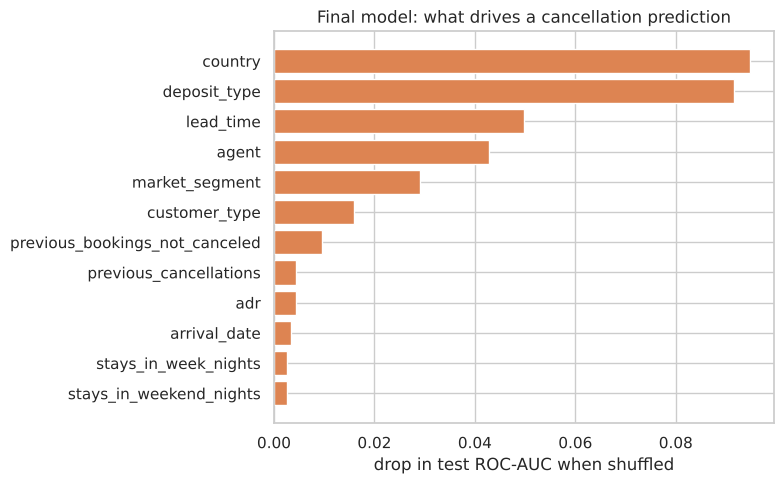

country                           0.0948
deposit_type                      0.0916
lead_time                         0.0499
agent                             0.0429
market_segment                    0.0291
customer_type                     0.0160
previous_bookings_not_canceled    0.0096
previous_cancellations            0.0043
dtype: float64

In [22]:
Xs = X_test.sample(6000, random_state=1); ys = y_test.loc[Xs.index]
r = permutation_importance(final_model, Xs, ys, scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE)
imp = pd.Series(r.importances_mean, index=Xs.columns)
imp = imp.sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="#DD8452")
ax.set_xlabel("drop in test ROC-AUC when shuffled")
ax.set_title("Final model: what drives a cancellation prediction")
fig.tight_layout(); save(fig, "final_importance"); plt.show()
imp[::-1].round(4).head(8)

**Takeaway:** on future bookings the model relies most on **country, deposit type, lead time, agent and market
segment** — the same drivers found in the EDA, so the model is learning business-meaningful patterns rather than
artefacts. `country` is the #1 driver, which makes validating how it is recorded (limitation #1) important.

## 9. Save the model

In [23]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump({"model": final_model, "threshold": THRESHOLD, "cost_ratio_c": BASE_C, "name": FINAL,
             "best_params": best_params}, MODEL_DIR / "final_model.joblib", compress=3)
test_results.to_csv(MODEL_DIR / "test_results.csv")
print("saved models/final_model.joblib")

saved models/final_model.joblib


## 10. Conclusion
* **Final system:** tuned XGBoost inside a leak-free pipeline that uses **only information available when the
  booking is created**; tuned and selected with forward-in-time validation; retrained monthly.
* **Value vs. today:** test ROC-AUC **0.840 (95% CI 0.829–0.852) vs 0.691** for the segment rule; for the same
  contact effort (30% of bookings) it finds **55% vs 44%** of cancellations; with cheap actions (c ≤ 1) it cuts the
  cost of cancellations by 13–34% vs the best simple policy.
* **Range:** 0.795 (without `country`) to 0.878 (if post-booking information were available early); 0.78 on single,
  non-group bookings.
* **Before deployment:** confirm when `country` is recorded, agree the cost ratio c with the revenue team,
  re-calibrate the probabilities on recent months, retrain monthly, and A/B-test the actions.